# Fraud Detection — Walkthrough

**Author:** Seyedmohammad (Ehsan) Ghoreishi
**Focus:** fraud / risk / financial-crime analytics

From a raw transaction log to an explained alert queue: simulate a card
portfolio → understand the fraud typologies → build point-in-time customer
features → select a model out of time → set the threshold by business cost
→ compare with a rule engine → explain individual alerts.

With ~0.5% fraud, **accuracy is a trap**: "never fraud" is 99.5% accurate.
Everything below is measured with PR-AUC, recall, precision, euros caught
and euros lost.

> Install the package first (`pip install -e .` from the repo root).

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image

from fraud_detection.eda import plot_overview, summarise
from fraud_detection.features import add_behavioural_features
from fraud_detection.model import train_and_evaluate
from fraud_detection.simulation import simulate_transactions
from fraud_detection.validation import out_of_time_split

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 140)

## 1. A card portfolio, not a table of independent rows

2,500 customers over six months, each with their own spend level, active
hours, devices and travel. Legitimate behaviour deliberately overlaps with
fraud signals (trips abroad, new phones, shopping bursts, night owls).
Fraud arrives in four typologies, shifts mix after April, and ~5% of it is
never reported — `fraud_type` keeps the truth for analysis only.

In [2]:
log = simulate_transactions()
print(f"{len(log):,} transactions | {log.customer_id.nunique():,} customers | "
      f"reported fraud rate {log.is_fraud.mean():.2%}")
log.head()

257,573 transactions | 2,499 customers | reported fraud rate 0.53%


,transaction_id,timestamp,customer_id,merchant_id,merchant_category,merchant_risk,channel,device_id,foreign_country,distance_from_home,amount,is_fraud,fraud_type
0,0,2026-01-01 00:11:48,1057,722,grocery,0.140,in_store,,0,12.400,20.030,0,none
1,1,2026-01-01 00:14:58,197,391,grocery,0.066,in_store,,0,1.300,27.550,0,none
2,2,2026-01-01 00:27:22,728,831,fuel,0.133,in_store,,0,1.500,3.800,0,none
3,3,2026-01-01 00:32:11,558,1203,online_retail,0.193,online,c558-d0,0,0.300,42.950,0,none
4,4,2026-01-01 00:49:22,1395,682,grocery,0.071,in_store,,0,10.200,33.620,0,none


## 2. How each typology looks

In [3]:
enriched = add_behavioural_features(log)
summarise(enriched)

,transactions,reported,median_amount,amount_vs_usual,online,new_device,foreign,night
fraud_type,,,,,,,,
legit,256116,0.000,26.350,1.000,0.397,0.025,0.022,0.044
card_testing,607,0.942,2.640,0.150,1.000,1.000,0.361,0.183
account_takeover,450,0.978,128.470,4.332,1.000,0.876,0.244,0.258
cloned_card,256,0.965,136.515,3.964,0.000,0.000,0.590,0.016
stealth,144,0.729,33.360,1.293,0.375,0.014,0.000,0.035


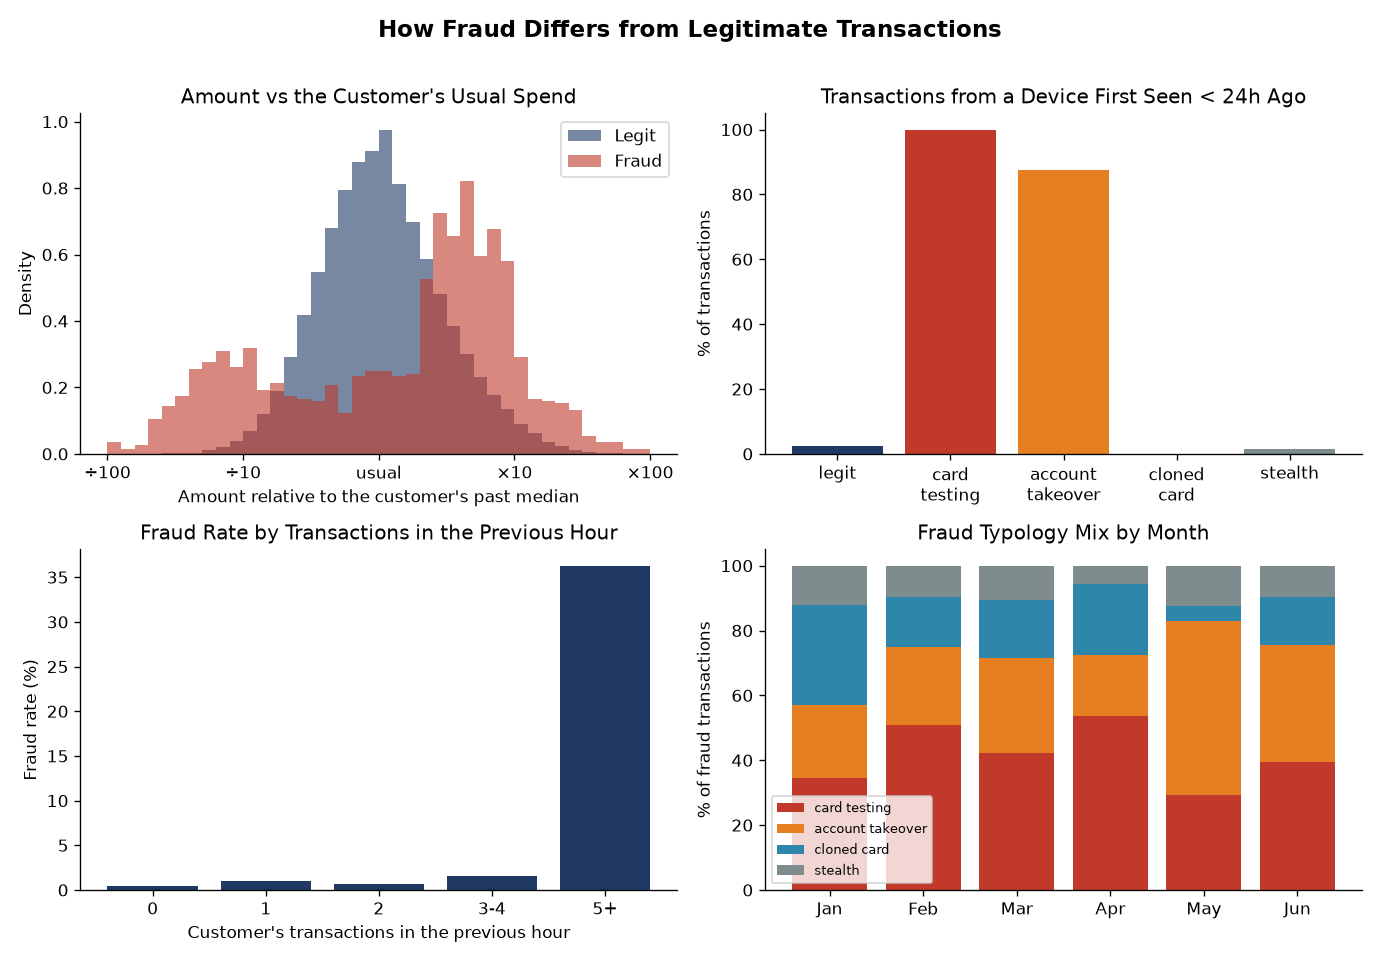

In [4]:
fig_path = Path(tempfile.gettempdir()) / "eda_overview.png"
plot_overview(enriched, fig_path)
Image(fig_path)

## 3. Point-in-time behavioural features

"Unusual" only means something relative to the customer. Every feature
below is computed from the customer's **earlier** transactions only — the
values a feature store would serve at authorisation time. One account
takeover, as the model sees it:

In [5]:
ato = enriched[enriched.fraud_type == "account_takeover"].customer_id.iloc[0]
start = enriched[(enriched.customer_id == ato)
                 & (enriched.fraud_type == "account_takeover")].timestamp.min()
window = enriched[(enriched.customer_id == ato)
                  & enriched.timestamp.between(start - pd.Timedelta(days=3),
                                               start + pd.Timedelta(hours=8))]
window[["timestamp", "amount", "merchant_category", "channel", "device_id",
        "amount_vs_customer_median", "device_age_days", "txn_count_1h",
        "fraud_type"]]

,timestamp,amount,merchant_category,channel,device_id,amount_vs_customer_median,device_age_days,txn_count_1h,fraud_type
8506,2026-01-07 05:32:46,35.890,grocery,in_store,,1.757,30.000,0.000,none
11804,2026-01-09 12:27:44,39.160,restaurant,in_store,,1.391,30.000,0.000,none
11853,2026-01-09 12:49:33,89.250,fuel,in_store,,2.487,30.000,1.000,none
11860,2026-01-09 12:50:54,72.960,fuel,in_store,,1.944,30.000,2.000,none
11893,2026-01-09 13:08:26,29.560,grocery,in_store,,0.755,30.000,3.000,none
12535,2026-01-09 20:01:49,255.220,electronics,online,fraud-279,6.801,0.000,0.000,account_takeover
12562,2026-01-09 20:20:55,229.070,online_retail,online,fraud-279,5.850,0.013,1.000,account_takeover
12743,2026-01-10 01:03:39,163.670,electronics,online,fraud-279,2.920,0.210,0.000,account_takeover


## 4. Out-of-time split

Train on January–April, test on May–June. A random split would let the
model learn from the future and hide the drift in fraud tactics.

In [6]:
train, test, cut = out_of_time_split(enriched.sort_values("timestamp"), "2026-05-01")
pd.DataFrame({"transactions": [len(train), len(test)],
              "fraud_rate": [train.is_fraud.mean(), test.is_fraud.mean()]},
             index=["train (Jan-Apr)", "test (May-Jun)"])

,transactions,fraud_rate
train (Jan-Apr),170775,0.005
test (May-Jun),86798,0.005


## 5. Model selection, threshold and evaluation

`train_and_evaluate` compares three candidates with **forward-chaining**
cross-validation, tunes the threshold on those out-of-fold predictions so
that *missed fraud (amount + €20 chargeback fee) + €5 per false alarm* is
minimal, then scores the untouched test period once.

In [7]:
out = train_and_evaluate(data=log, reports_dir=None)
s = out["summary"]
pd.DataFrame(s["models"]).T

,cv_pr_auc,cv_roc_auc,test_pr_auc,test_roc_auc,test_brier
logistic_regression,0.493,0.957,NaN,NaN,NaN
random_forest,0.722,0.961,NaN,NaN,NaN
gradient_boosting,0.750,0.963,0.733,0.970,0.003


In [8]:
pd.Series({
    "threshold": s["cost_optimal_threshold"],
    "recall": s["recall_fraud"],
    "precision": s["precision_fraud"],
    "fraud value caught": s["value_recall"],
    "alerts per day": s["alerts_per_day"],
    "test cost (EUR)": s["business_cost"]["test_cost_at_threshold"],
    "cost without model (EUR)": s["business_cost"]["test_cost_without_model"],
}).to_frame("test period")

,test period
threshold,0.090
recall,0.832
precision,0.395
fraud value caught,0.924
alerts per day,16.000
test cost (EUR),"9,257.090"
cost without model (EUR),"71,627.130"


## 6. Is it better than rules?

The question a fraud manager asks. At exactly the same number of alerts as
a typical four-rule engine:

In [9]:
rb = s["rules_baseline"]
pd.DataFrame({"rule engine": rb["rules"], "model": rb["model_same_alerts"]})

,rule engine,model
recall,0.619,0.866
precision,0.136,0.190


## 7. Where it fails

Aggregate recall hides the blind spot: stealth fraud looks like the
customer's own spending and is almost never caught. That's a finding to
take to the business (e.g. cardholder alerts), not something to tune away.

In [10]:
pd.DataFrame(s["recall_by_typology"]).T

,transactions,recall,value_recall
card_testing,166.000,0.880,0.991
account_takeover,222.000,0.905,0.929
cloned_card,46.000,1.000,1.000
stealth,54.000,0.019,0.005


In [11]:
pd.DataFrame(s["performance_by_month"]).T

,pr_auc,recall,fraud_rate
2026-05,0.707,0.816,0.006
2026-06,0.765,0.850,0.005


## 8. Explained alerts

Every alert carries reason codes an analyst can act on:

In [12]:
out["sample_alerts"][["amount", "merchant_category", "channel", "score",
                       "reasons", "fraud_type"]].head(8)

,amount,merchant_category,channel,score,reasons,fraud_type
239043,325.570,gift_cards,online,1.000,recently first-seen device; small test charges...,card_testing
239038,1.990,digital_goods,online,1.000,recently first-seen device; small test charges...,card_testing
256213,157.430,gift_cards,online,1.000,recently first-seen device; small test charges...,card_testing
187679,422.700,gift_cards,online,1.000,recently first-seen device; small test charges...,card_testing
215365,149.110,jewelry,in_store,1.000,far from home; large amount; risky merchant ca...,cloned_card
211479,226.060,fuel,in_store,1.000,far from home; large amount; risky merchant ca...,cloned_card
186257,269.430,travel,online,1.000,recently first-seen device; high spend in the ...,account_takeover
199317,168.300,gift_cards,online,1.000,recently first-seen device; large amount; high...,account_takeover


## Takeaway

On data that is genuinely hard, the model catches ~83% of fraud
transactions and ~92% of fraudulent value at 16 alerts a day, and finds
~25 points more fraud than a rule engine for the same analyst workload.
The real deliverable is the **framework**: point-in-time features,
out-of-time evaluation, a cost-based threshold, an honest view of blind
spots and an explanation for every alert — what a Customer Risk / AFC team
owns day to day.